In [7]:
# ============================================
# OS1 MULTIMODAL — Analyse IEMOCAP réel
# ============================================

import sys
sys.path.append('../backend')
from iemocap_parser import (
    charger_iemocap_complet,
    analyser_distribution,
    sauvegarder_iemocap_csv
)

# Charger IEMOCAP complet
df_iemocap = charger_iemocap_complet(sessions=[1, 2, 3, 4, 5])

# Analyser la distribution
analyser_distribution(df_iemocap)

# Sauvegarder
sauvegarder_iemocap_csv(df_iemocap)

# Aperçu
print("\n=== APERÇU DONNÉES ===")
print(df_iemocap.head(10))

Chargement IEMOCAP sessions [1, 2, 3, 4, 5]...
  ✅ Session1 : 28 fichiers
  ✅ Session2 : 30 fichiers
  ✅ Session3 : 32 fichiers
  ✅ Session4 : 30 fichiers
  ✅ Session5 : 31 fichiers

✅ Total IEMOCAP chargé : 10039 utterances

=== DISTRIBUTION ÉMOTIONS IEMOCAP ===

Émotions originales :
emotion
xxx    2507
fru    1849
neu    1708
ang    1103
sad    1084
exc    1041
hap     595
sur     107
fea      40
oth       3
dis       2
Name: count, dtype: int64

États DAiSEE mappés :
etat_daisee
Boredom        5302
Frustration    2954
Engagement     1636
Confusion       147
Name: count, dtype: int64

Statistiques dimensionnelles :
  Valence moyenne    : 2.78
  Activation moyenne : 3.09
  Dominance moyenne  : 3.19
✅ IEMOCAP sauvegardé : C:\Users\Lenovo\EmoLearn\notebooks\../backend\../data/iemocap_parsed.csv

=== APERÇU DONNÉES ===
          utterance_id  start_time  end_time  duree emotion  valence  \
0  Ses01F_impro01_F000      6.2901    8.2357   1.95     neu      2.5   
1  Ses01F_impro01_F001    

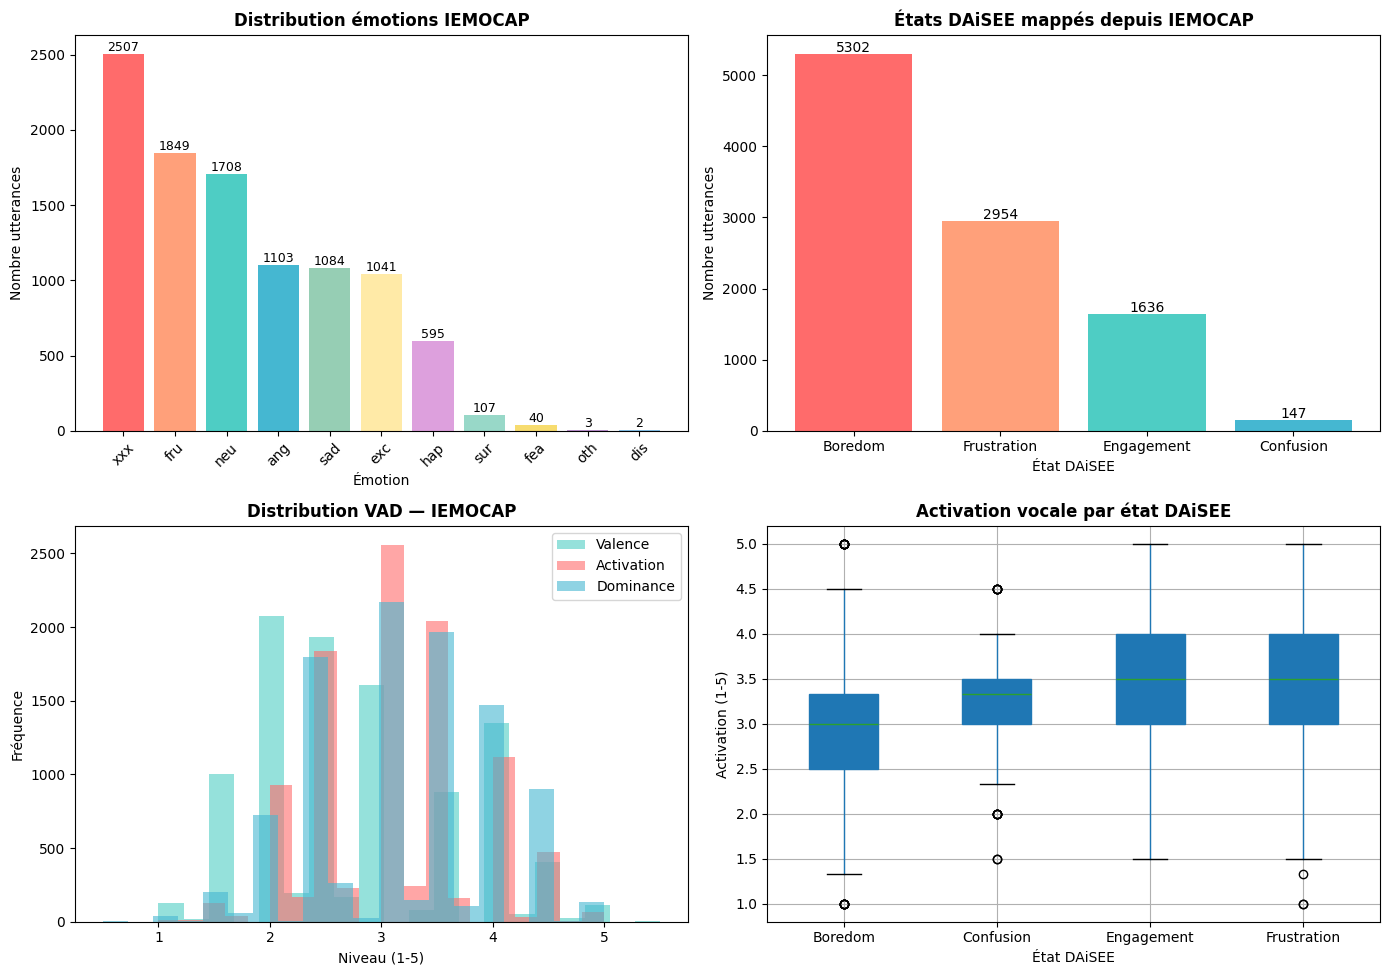

✅ Visualisations IEMOCAP sauvegardées !


In [8]:
# ============================================
# VISUALISATIONS IEMOCAP
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Analyse IEMOCAP — Dataset multimodal réel',
             fontsize=16, fontweight='bold')

# ===== Graphique 1 — Distribution émotions originales =====
emotion_counts = df_iemocap['emotion'].value_counts()
colors1 = ['#FF6B6B','#FFA07A','#4ECDC4','#45B7D1',
           '#96CEB4','#FFEAA7','#DDA0DD','#98D8C8','#F7DC6F','#BB8FCE','#85C1E9']
axes[0,0].bar(emotion_counts.index, emotion_counts.values,
              color=colors1[:len(emotion_counts)])
axes[0,0].set_title('Distribution émotions IEMOCAP', fontweight='bold')
axes[0,0].set_xlabel('Émotion')
axes[0,0].set_ylabel('Nombre utterances')
axes[0,0].tick_params(axis='x', rotation=45)
for i, (k, v) in enumerate(emotion_counts.items()):
    axes[0,0].text(i, v + 20, str(v), ha='center', fontsize=9)

# ===== Graphique 2 — États DAiSEE mappés =====
daisee_counts = df_iemocap['etat_daisee'].value_counts()
colors2 = ['#FF6B6B', '#FFA07A', '#4ECDC4', '#45B7D1']
axes[0,1].bar(daisee_counts.index, daisee_counts.values,
              color=colors2[:len(daisee_counts)])
axes[0,1].set_title('États DAiSEE mappés depuis IEMOCAP', fontweight='bold')
axes[0,1].set_xlabel('État DAiSEE')
axes[0,1].set_ylabel('Nombre utterances')
for i, (k, v) in enumerate(daisee_counts.items()):
    axes[0,1].text(i, v + 30, str(v), ha='center', fontsize=10)

# ===== Graphique 3 — Distribution VAD= modèle dimensionnel des émotions (3 axes numériques), en complément des labels discrets (hap, fru, neu…).

 
axes[1,0].hist(df_iemocap['valence'],    bins=20, alpha=0.6,
               color='#4ECDC4', label='Valence')
axes[1,0].hist(df_iemocap['activation'], bins=20, alpha=0.6,
               color='#FF6B6B', label='Activation')
axes[1,0].hist(df_iemocap['dominance'],  bins=20, alpha=0.6,
               color='#45B7D1', label='Dominance')
axes[1,0].set_title('Distribution VAD — IEMOCAP', fontweight='bold')
axes[1,0].set_xlabel('Niveau (1-5)')
axes[1,0].set_ylabel('Fréquence')
axes[1,0].legend()

# ===== Graphique 4 — Activation par émotion =====
df_iemocap.boxplot(
    column  = 'activation',
    by      = 'etat_daisee',
    ax      = axes[1,1],
    patch_artist = True
)
axes[1,1].set_title('Activation vocale par état DAiSEE', fontweight='bold')
axes[1,1].set_xlabel('État DAiSEE')
axes[1,1].set_ylabel('Activation (1-5)')
plt.suptitle('')

plt.tight_layout()
plt.savefig('../data/iemocap_analyse.png', dpi=150)
plt.show()
print("✅ Visualisations IEMOCAP sauvegardées !")

In [1]:
# Test SER

import sys
sys.path.append('../backend')
# Teste la voix pour scénarios 0, 5, 10, 15…
#Retourne : émotion IEMOCAP, état DAiSEE, niveau, score

from ser_module import analyser_voix_depuis_scenario, get_statistiques_iemocap

print("=== TEST SER IEMOCAP RÉEL ===\n")

# Statistiques
stats = get_statistiques_iemocap()
print(f"Total utterances : {stats['total']}")
print(f"Distribution DAiSEE : {stats['etats_daisee']}")
print(f"Activation moyenne  : {stats['activation_mean']:.2f}")

print("\n=== TEST ANALYSE VOCALE ===\n")
for i in [0, 10, 25, 40, 49]:
    result = analyser_voix_depuis_scenario(scenario_id=i)
    print(f"Scénario {i:2d} → Émotion : {result['emotion']:4s} | État : {result['etat']:12s} | Niveau : {result['niveau']} | Score : {result['score']:.2f}")

✅ Parser IEMOCAP chargé !
✅ Module SER IEMOCAP réel chargé !
=== TEST SER IEMOCAP RÉEL ===

✅ IEMOCAP chargé depuis CSV : 10039 utterances
Total utterances : 10039
Distribution DAiSEE : {'Boredom': 5302, 'Frustration': 2954, 'Engagement': 1636, 'Confusion': 147}
Activation moyenne  : 3.09

=== TEST ANALYSE VOCALE ===

Scénario  0 → Émotion : neu  | État : Boredom      | Niveau : 1 | Score : 0.38
Scénario 10 → Émotion : xxx  | État : Boredom      | Niveau : 1 | Score : 0.62
Scénario 25 → Émotion : fru  | État : Frustration  | Niveau : 3 | Score : 0.62
Scénario 40 → Émotion : sad  | État : Boredom      | Niveau : 2 | Score : 0.12
Scénario 49 → Émotion : sad  | État : Boredom      | Niveau : 2 | Score : 0.12


In [ ]:
# ============================================
# TEST PIPELINE MULTIMODAL COMPLET
# DAiSEE (visage) + IEMOCAP (voix) + Fusion
# ============================================

import sys
sys.path.append('../backend')
from fer_module    import analyser_visage_depuis_scenario
from ser_module    import analyser_voix_depuis_scenario
from fusion_module import fusionner_modalites, expliquer_fusion

import pandas as pd

# Charger les 50 scénarios DAiSEE
df_scenarios = pd.read_csv('../data/scenarios_50.csv')
df_scenarios.columns = df_scenarios.columns.str.strip()

print("=== TEST PIPELINE MULTIMODAL COMPLET ===\n")

for scenario_id in [0, 5, 10, 20, 30, 40, 49]:
    scenario = df_scenarios.iloc[scenario_id]

    # Modalité 1 — Visage (DAiSEE)
    result_visage = analyser_visage_depuis_scenario(scenario)

    # Modalité 2 — Voix (IEMOCAP)
    result_voix = analyser_voix_depuis_scenario(scenario_id)

    # Fusion multimodale
    fusion = fusionner_modalites(result_visage, result_voix)

    print(f"Scénario {scenario_id:2d} :")
    print(f"  👁️  Visage (DAiSEE)  : {result_visage['etat']:12s} niveau {result_visage['niveau']}")
    print(f"  🎤 Voix  (IEMOCAP)  : {result_voix['etat']:12s} niveau {result_voix['niveau']} (émotion: {result_voix['emotion']})")
    print(f"  🔀 Fusion finale    : {fusion['etat']:12s} niveau {fusion['niveau']} — {'⚠️ Conflit' if fusion['conflit'] else '✅ Accord'}")
    print(f"  📋 Stratégie       : {fusion['strategie_fusion']}")
    print()

In [ ]:
# ============================================
# COMPARAISON FINALE DAiSEE vs IEMOCAP
# ============================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Recharger les données nécessaires
df_iemocap  = pd.read_csv('../data/iemocap_parsed.csv')
df_scenarios = pd.read_csv('../data/scenarios_50.csv')
df_scenarios.columns = df_scenarios.columns.str.strip()

print(f"✅ IEMOCAP : {len(df_iemocap)} utterances")
print(f"✅ Scénarios : {len(df_scenarios)} scénarios")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Comparaison DAiSEE vs IEMOCAP — Analyse multimodale',
             fontsize=14, fontweight='bold')

# ===== Graphique 1 — Distribution états DAiSEE =====
daisee_etats = {
    'Boredom'    : 1229,
    'Confusion'  : 497,
    'Engagement' : 5111,
    'Frustration': 234
}
couleurs = ['#FF6B6B', '#45B7D1', '#4ECDC4', '#FFA07A']
axes[0,0].bar(daisee_etats.keys(), daisee_etats.values(), color=couleurs)
axes[0,0].set_title('DAiSEE — États engagement\n(modalité visage)', fontweight='bold')
axes[0,0].set_ylabel('Nombre de clips')
for i, (k, v) in enumerate(daisee_etats.items()):
    axes[0,0].text(i, v + 50, str(v), ha='center', fontsize=10)

# ===== Graphique 2 — Distribution états IEMOCAP =====
iemocap_etats = df_iemocap['etat_daisee'].value_counts()
axes[0,1].bar(iemocap_etats.index, iemocap_etats.values,
              color=['#FF6B6B', '#FFA07A', '#4ECDC4', '#45B7D1'])
axes[0,1].set_title('IEMOCAP — États mappés\n(modalité voix)', fontweight='bold')
axes[0,1].set_ylabel('Nombre utterances')
for i, (k, v) in enumerate(iemocap_etats.items()):
    axes[0,1].text(i, v + 50, str(v), ha='center', fontsize=10)

# ===== Graphique 3 — Résultats fusion sur 50 scénarios =====
resultats_fusion = []
for i in range(len(df_scenarios)):
    scenario   = df_scenarios.iloc[i]
    res_visage = analyser_visage_depuis_scenario(scenario)
    res_voix   = analyser_voix_depuis_scenario(i)
    fusion     = fusionner_modalites(res_visage, res_voix)
    resultats_fusion.append(fusion['etat'])

fusion_counts = pd.Series(resultats_fusion).value_counts()
axes[1,0].bar(fusion_counts.index, fusion_counts.values,
              color=['#FF6B6B', '#4ECDC4', '#FFA07A', '#45B7D1'])
axes[1,0].set_title('Fusion multimodale\n(50 scénarios)', fontweight='bold')
axes[1,0].set_ylabel('Nombre de scénarios')
for i, (k, v) in enumerate(fusion_counts.items()):
    axes[1,0].text(i, v + 0.3, str(v), ha='center', fontsize=11)

# ===== Graphique 4 — Conflits détectés =====
conflits = []
for i in range(len(df_scenarios)):
    scenario   = df_scenarios.iloc[i]
    res_visage = analyser_visage_depuis_scenario(scenario)
    res_voix   = analyser_voix_depuis_scenario(i)
    fusion     = fusionner_modalites(res_visage, res_voix)
    conflits.append('Conflit' if fusion['conflit'] else 'Accord')

conflit_counts = pd.Series(conflits).value_counts()
axes[1,1].pie(
    conflit_counts.values,
    labels     = conflit_counts.index,
    autopct    = '%1.1f%%',
    colors     = ['#FF6B6B', '#4ECDC4'],
    startangle = 90
)
axes[1,1].set_title('Accords vs Conflits\n(50 scénarios fusionnés)', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/comparaison_daisee_iemocap.png', dpi=150)
plt.show()
print("✅ Comparaison DAiSEE vs IEMOCAP sauvegardée !")

In [ ]:
# ============================================
# RÉSUMÉ FINAL OS1 MULTIMODAL
# ============================================

print("=" * 60)
print("    RÉSUMÉ FINAL OS1 — MULTIMODAL")
print("=" * 60)

print("\n📊 DATASET DAiSEE (Modalité Visage)")
print(f"   Total clips        : 8 571")
print(f"   Patterns critiques : 6 patterns")
print(f"   Transitions        : 189 cas")
print(f"   Alertes confirmées : 404 cas")
print(f"   Scénarios créés    : 50")

print("\n🎤 DATASET IEMOCAP (Modalité Voix)")
print(f"   Total utterances   : {len(df_iemocap)}")
print(f"   Sessions           : 5 sessions")
print(f"   Émotions           : 9 catégories")
print(f"   Boredom mappé      : {df_iemocap[df_iemocap['etat_daisee']=='Boredom'].shape[0]}")
print(f"   Frustration mappée : {df_iemocap[df_iemocap['etat_daisee']=='Frustration'].shape[0]}")
print(f"   Engagement mappé   : {df_iemocap[df_iemocap['etat_daisee']=='Engagement'].shape[0]}")
print(f"   Confusion mappée   : {df_iemocap[df_iemocap['etat_daisee']=='Confusion'].shape[0]}")

# Calculer conflits sur 50 scénarios
accords   = conflits.count('Accord')
conf_list = conflits.count('Conflit')

print("\n🔀 FUSION MULTIMODALE (50 scénarios)")
print(f"   Accords            : {accords} ({accords/50*100:.0f}%)")
print(f"   Conflits           : {conf_list} ({conf_list/50*100:.0f}%)")
print(f"   Stratégie dominante: Priorité pédagogique")

print("\n📁 FICHIERS SAUVEGARDÉS")
print(f"   - data/distribution_etats.png")
print(f"   - data/correlation_etats.png")
print(f"   - data/boxplots_etats.png")
print(f"   - data/trajectoires_temporelles.png")
print(f"   - data/scenarios_50.csv")
print(f"   - data/iemocap_parsed.csv")
print(f"   - data/iemocap_analyse.png")
print(f"   - data/comparaison_daisee_iemocap.png")

print(f"\n✅ OS1 MULTIMODAL TERMINÉ AVEC SUCCÈS !")
print("=" * 60)